## Deep Agents overview
Build agents that can plan, use subagents, and leverage file systems for complex tasks

deepagents is a standalone library for building agents that can tackle complex, multi-step tasks. Built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus, deep agents come with planning capabilities, file systems for context management, and the ability to spawn subagents.

## When to use deep agents
Use deep agents when you need agents that can:

Handle complex, multi-step tasks that require planning and decomposition
Manage large amounts of context through file system tools
Delegate work to specialized subagents for context isolation
Persist memory across conversations and threads

In [10]:
# ============================================================
# 1. IMPORTS
# ============================================================
import truststore
truststore.inject_into_ssl()

import os
from typing import Literal

from dotenv import load_dotenv
from tavily import TavilyClient

from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain.agents import create_agent

from deepagents import create_deep_agent



In [11]:
# ============================================================
# 2. ENVIRONMENT CONFIGURATION
# ============================================================

load_dotenv()

GROQ_API_KEY = os.getenv("GROQ_API_KEY")
TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")

if not GROQ_API_KEY:
    raise ValueError("GROQ_API_KEY is missing from .env")

if not TAVILY_API_KEY:
    raise ValueError("TAVILY_API_KEY is missing from .env")

In [12]:
# ============================================================
# 3. INITIALIZE TAVILY CLIENT
# ============================================================

tavily_client = TavilyClient(
    api_key=TAVILY_API_KEY
)

In [14]:
# ============================================================
# 4. DEFINE INTERNET SEARCH TOOL
# ============================================================

@tool
def web_search(
    query: str,
    max_results: int = 2,
    topic: Literal["general", "news", "finance"] = "general"
) -> dict:
    """
    Search the internet for reliable and relevant information.

    Args:
        query: The search query.
        max_results: Maximum number of search results.
        topic: Search category - general, news or finance.

    Returns:
        Search results containing titles, URLs and content.
    """

    response = tavily_client.search(
        query=query,
        max_results=max_results,
        topic=topic,
        include_raw_content=False
    )

    return response


# Register tools in one place.
tools = [web_search]

In [20]:
# ============================================================
# 5. INITIALIZE GROQ LLM
# ============================================================

model = init_chat_model(
    model="groq:openai/gpt-oss-20b",
    temperature=0,
    max_retries=2,
    timeout=60
)

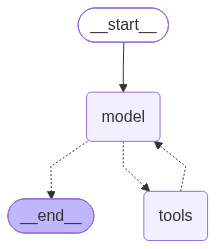

In [21]:
# ============================================================
# 6. CREATE A BASIC LANGCHAIN AGENT
# ============================================================

basic_agent = create_agent(
    model=model,
    tools=tools,
    system_prompt=(
        "You are a helpful research assistant. "
        "Use the web search tool whenever current information "
        "or external research is required. "
        "Provide accurate, structured and concise answers."
    )
)

basic_agent

In [23]:
# ============================================================
# 8. EXECUTE BASIC AGENT
# ============================================================
question = (
        "Research the latest developments in Agentic AI. "
        "Explain its architecture, major frameworks, "
        "real-world applications and future possibilities."
    )
response = basic_agent.invoke(
        {   
            "messages": [
                {
                    "role": "user",
                    "content": question
                }
            ]
        }
    )

print("\n========== BASIC AGENT ==========\n")
response


========== BASIC AGENT ==========



{'messages': [HumanMessage(content='Research the latest developments in Agentic AI. Explain its architecture, major frameworks, real-world applications and future possibilities.', additional_kwargs={}, response_metadata={}, id='2e3c1782-a9fe-4ab2-a317-b49fc411147d'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to research latest developments in Agentic AI. Provide architecture, major frameworks, real-world applications, future possibilities. Must use web search. Let's search.", 'tool_calls': [{'id': 'fc_42c21c89-6bb5-46e3-b3bd-afcc62700e62', 'function': {'arguments': '{"max_results":10,"query":"latest developments in Agentic AI architecture major frameworks real-world applications future possibilities","topic":"general"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 80, 'prompt_tokens': 253, 'total_tokens': 333, 'completion_time': 0.088646551, 'completion_tokens_details': {'reasoning_tokens': 33}, 'p

In [24]:
print(response["messages"][-1].content)

**Agentic AI – 2026 Snapshot**

| Section | Key Take‑aways | Representative Sources |
|---------|----------------|------------------------|
| **What is Agentic AI?** | Goal‑driven, context‑aware systems that *plan, act, learn, and reflect* using LLMs as the core reasoning engine. They can call external tools (APIs, databases, code, web‑scrapers) and maintain long‑term memory. | MDPI survey (2026) – “Agentic AI: A Perspective on Architecture, Frameworks and Applications” |
| **Core Architecture** | 1. **LLM Backbone** – the reasoning engine (e.g., GPT‑4o, Llama‑3, Claude‑3). <br>2. **Planner** – generates a sequence of sub‑tasks or tool calls (often via a policy network or RL‑based planner). <br>3. **Executor** – runs the plan, calling tools or APIs, and returns results. <br>4. **Memory Store** – short‑term (working memory) + long‑term (vector store, relational DB). <br>5. **Tool Registry / Skill Library** – standardized interfaces (OpenAPI, MCP) for external services. <br>6. **Orchestr

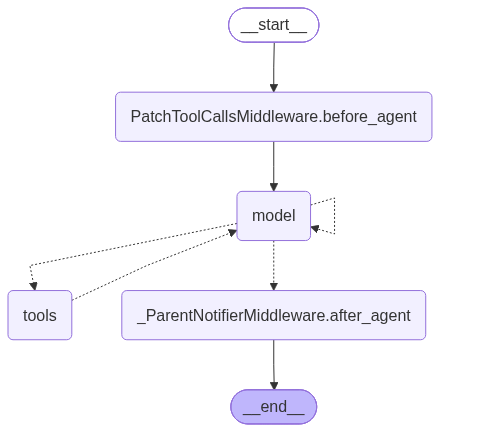

In [30]:
# ============================================================
# 7. CREATE A DEEP AGENT
# ============================================================
from langchain_ollama import ChatOllama
## Ollama qwen2.5:3b
# Initialize the modern Ollama chat model
model = ChatOllama(
    model="qwen2.5:3b",
    temperature=0
)


deep_agent = create_deep_agent(
    model=model,
    tools=tools,
    system_prompt="""
    You are an expert research assistant.

    Your responsibilities:

    1. Understand the user's research objective.
    2. Break complex tasks into smaller steps.
    3. Create a research plan before executing complex tasks.
    4. Use web search to gather relevant information.
    5. Verify important information using multiple sources.
    6. Analyze and synthesize the collected information.
    7. Present the final answer in a structured format.

    Do not invent facts or sources.
    Clearly identify uncertainty when information is unavailable.
    """
)

deep_agent

In [ ]:
# ============================================================
# 9. EXECUTE DEEP AGENT
# ============================================================
response = deep_agent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": question
                }
            ]
        }
    )

print("\n========== DEEP AGENT ==========\n")
response


========== DEEP AGENT ==========



{'messages': [HumanMessage(content='Research the latest developments in Agentic AI. Explain its architecture, major frameworks, real-world applications and future possibilities.', additional_kwargs={}, response_metadata={}, id='3892e88c-2711-40d4-bd0a-deea0d265e5a'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen2.5:3b', 'created_at': '2026-11-02T15:04:19.752169Z', 'done': True, 'done_reason': 'stop', 'total_duration': 5908755959, 'load_duration': 28104250, 'prompt_eval_count': 2502, 'prompt_eval_duration': 4892015000, 'eval_count': 46, 'eval_duration': 856382000, 'logprobs': None, 'model_name': 'qwen2.5:3b', 'model_provider': 'ollama'}, id='lc_run--01a19cca-1cf9-7470-86dd-1d10d32d1c68-0', tool_calls=[{'name': 'web_search', 'args': {'max_results': 10, 'topic': 'general', 'query': 'latest developments Agentic AI architecture major frameworks real-world applications future possibilities'}, 'id': '588a7c65-2d9f-4710-9d17-880b73aece7f', 'type': 'tool_call'}

In [32]:
print(response["messages"][-1].content)

Based on the information provided, here are some key points about Agentic AI as of 2026:

1. **Core Concepts**:
   - Agentic AI involves the use of AI agents that can work together in teams to solve complex problems. These agents can be human-assisted or fully autonomous.
   - The concept of multi-agent systems has evolved, with improvements in task performance and the ability to handle unbalanced communication.
   - Frameworks like Delegation Capability Tokens (DCT) from DeepMind have been introduced to formalize the delegation of tasks among agents.

2. **Technological Advancements**:
   - **Multi-Agent Systems**: These systems have shown improvements in task performance, especially when agents communicate and collaborate effectively.
   - **Dynamic Reasoning Frameworks**: These allow agents to adapt their reasoning based on new information or changing conditions.
   - **Retrieval-Augmented Generation (RAG)**: This technique enhances the contextual understanding and autonomy of AI ag

## What happened?
Your deep agent automatically:

1. Planned its approach: Used the built-in write_todos tool to break down the research task
2. Conducted research: Called the internet_search tool to gather information
3. Managed context: Used file system tools (write_file, read_file) to offload large search results
4. Spawned subagents (if needed): Delegated complex subtasks to specialized subagents
5. Synthesized a report: Compiled findings into a coherent response

Deep agents come with a built-in system prompt inspired by Claude Code’s system prompt. The default system prompt contains detailed instructions for using the built-in planning tool, file system tools, and subagents. Each deep agent tailored to a use case should include a custom system prompt specific to that use case.